# 02. Colour, demosaicing and white balance

A colour sensor does not record colour. Every pixel sits behind one filter and stores one number, so two thirds of the colour data is missing before the first line of processing. This notebook builds the mosaic (L3 s13), compares the ways of filling the gaps (L3 s17, s26-27), shows why colour can be treated more roughly than brightness (L3 s20-25), and then moves to the light source: colour temperature, the xy diagram and three ways of estimating white balance (L4 s5-11). Theory: `docs/02_color_sensing_demosaicing.md`, `docs/03_white_balance.md`.

In [1]:
%matplotlib inline
# JPEG keeps the executed notebooks small (plots are photographs).
%config InlineBackend.figure_format = 'jpeg'
import sys, pathlib, time
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 80
# Make `import isp` work whether Jupyter was started in the project root or in notebooks/.
_cwd = pathlib.Path.cwd().resolve()
ROOT = _cwd.parent if _cwd.name == 'notebooks' else _cwd
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import isp
from isp import utils, scenes
srgb = utils.linear_to_srgb      # linear light -> display values for imshow


def show_row(images, titles, figsize=(12, 4), cmap=None, vmin=None, vmax=None):
    # one row of image panels, axes off
    fig, axs = plt.subplots(1, len(images), figsize=figsize)
    for ax, im, t in zip(np.atleast_1d(axs), images, titles):
        ax.imshow(np.clip(im, 0, 1) if (vmin is None and im.ndim == 3) else im,
                  cmap=cmap, vmin=vmin, vmax=vmax, interpolation='nearest')
        ax.set_title(t, fontsize=10)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

from isp import cfa, demosaic, whitebalance as wb
import ipywidgets as W

scene = scenes.load('astronaut', 256)            # linear light, the ground truth
print(scene.shape, scene.dtype, 'patterns:', cfa.PATTERNS, 'methods:', demosaic.METHODS)

(256, 256, 3) float32 patterns: ('RGGB', 'BGGR', 'GRBG', 'GBRG') methods: ('nearest', 'bilinear', 'bicubic', 'median', 'malvar')


## The colour filter array

Four arrangements of the 2x2 Bayer tile are in use; the string is read row by row, so `RGGB` puts red at the top left. Green appears twice because the eye is most sensitive to it and it carries most of the luminance.

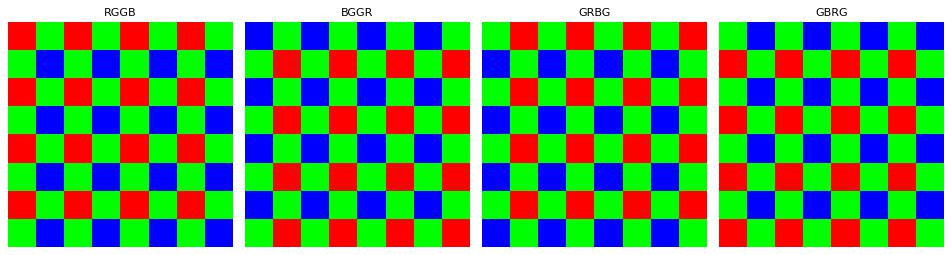

RGB image: 196608 numbers | mosaic: 65536 numbers | kept: 33 %


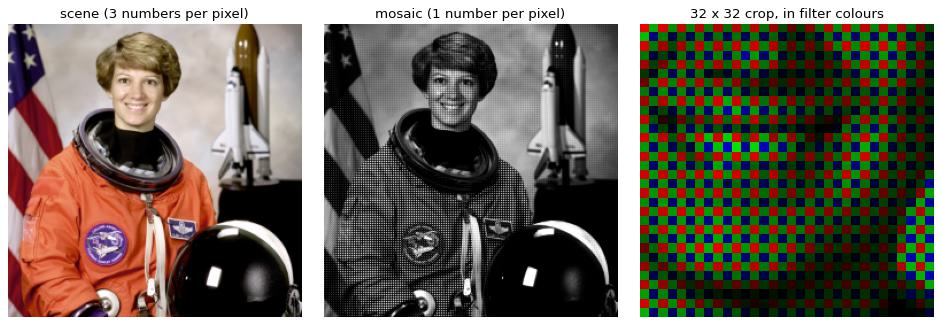

In [2]:
def show_patterns(patterns=cfa.PATTERNS, n=8, plot=True):
    tiles = [cfa.colorize(cfa.mosaic(np.ones((n, n, 3), np.float32), p), p) for p in patterns]
    if plot:
        show_row(tiles, list(patterns), figsize=(12, 3.4))
    return tiles

_ = show_patterns()

m = cfa.mosaic(scene)
print('RGB image:', scene.size, 'numbers | mosaic:', m.size, 'numbers | kept: %.0f %%' % (100 * m.size / scene.size))
fig, axs = plt.subplots(1, 3, figsize=(12, 4))
axs[0].imshow(srgb(scene)); axs[0].set_title('scene (3 numbers per pixel)')
axs[1].imshow(m, cmap='gray'); axs[1].set_title('mosaic (1 number per pixel)')
axs[2].imshow(cfa.colorize(m)[60:92, 100:132], interpolation='nearest'); axs[2].set_title('32 x 32 crop, in filter colours')
for ax in axs: ax.axis('off')
plt.tight_layout(); plt.show()

The mosaic looks like a grey photograph with a fine checker texture, which is the colour information encoded as brightness differences between neighbours. Demosaicing has to turn that back into three full planes.

## Demosaicing methods on a zone plate

A zone plate has spatial frequency that grows with the radius, so it shows where each interpolation starts to fail. The scene is grey, so every coloured fringe is an error (false colour). Methods: nearest, bilinear, bicubic, Freeman's median (L3 s26-27) and Malvar's gradient-corrected filter.

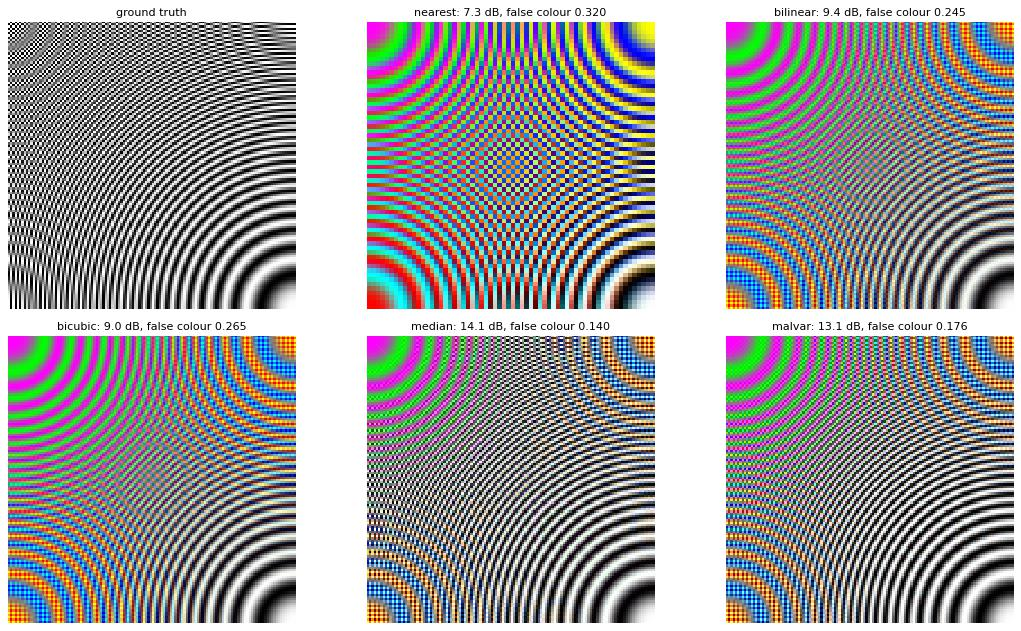

In [3]:
def compare_demosaic(img, methods=demosaic.METHODS, crop=None, plot=True, display=lambda x: x, **kw):
    # mosaic -> each method; returns {method: (psnr dB, false-colour error)}; grid of crops when plot=True
    m = cfa.mosaic(img)
    outs = {k: demosaic.demosaic(m, 'RGGB', k, **kw) for k in methods}
    res = {k: (utils.psnr(img, o), demosaic.false_color(o, img)) for k, o in outs.items()}
    if plot:
        sl = (slice(None), slice(None)) if crop is None else (slice(crop[0], crop[1]), slice(crop[2], crop[3]))
        fig, axs = plt.subplots(2, 3, figsize=(14, 8))
        panels = [('ground truth', img)] + [(k, outs[k]) for k in methods]
        for ax, (name, im) in zip(axs.ravel(), panels):
            ax.imshow(np.clip(display(im[sl]), 0, 1), interpolation='nearest'); ax.axis('off')
            ax.set_title(name if name == 'ground truth' else f'{name}: {res[name][0]:.1f} dB, false colour {res[name][1]:.3f}', fontsize=10)
        plt.tight_layout(); plt.show()
    return res

zp = scenes.zone_plate(256)
res_zp = compare_demosaic(zp, crop=(0, 128, 0, 128))

The crops show the top-left quarter, where the pattern is at its highest frequency. Nearest neighbour and bilinear show strong coloured moire; the methods that look across channels (median, Malvar) keep the colour error lower. A grey scene is a harsh test because any frequency above the sampling limit of the red and blue planes (half that of the full grid) aliases.

## The same on a photograph

On natural images the differences are smaller and live on edges. The metrics are over the whole image; the crop is a region of the astronaut shown through the sRGB curve.

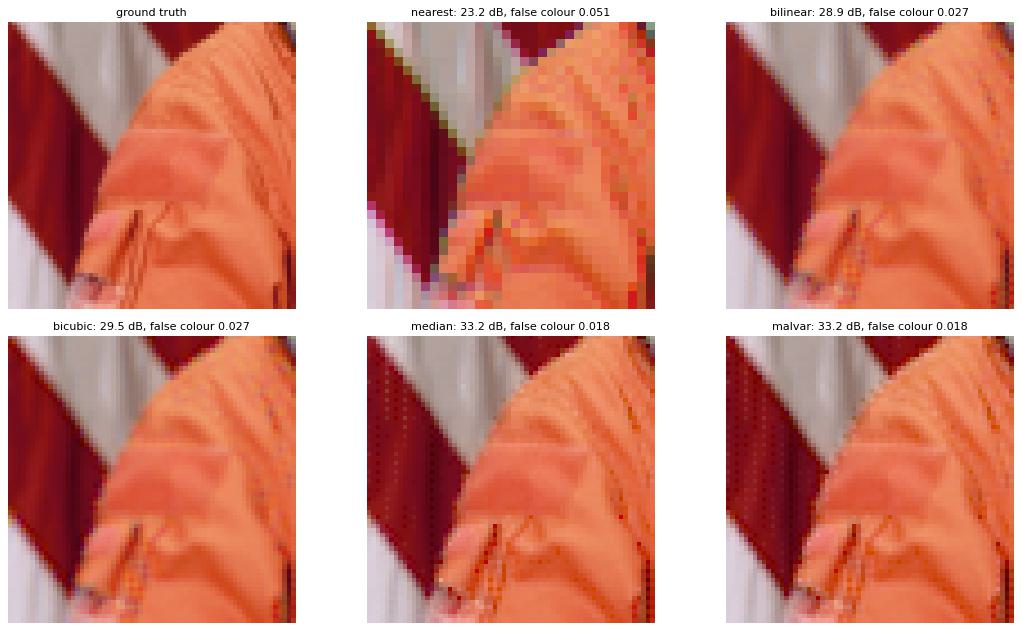

method      PSNR dB  false colour
nearest       23.21        0.0513
bilinear      28.91        0.0274
bicubic       29.48        0.0265
median        33.20        0.0176
malvar        33.15        0.0183


In [4]:
res_ph = compare_demosaic(scene, crop=(110, 174, 0, 64), display=srgb)
print('{:10s} {:>8s} {:>13s}'.format('method', 'PSNR dB', 'false colour'))
for k, (p, f) in res_ph.items():
    print('{:10s} {:8.2f} {:13.4f}'.format(k, p, f))

Higher PSNR and lower false colour go together here. Bilinear is the cheap baseline; once the method looks across channels, the colour fringes along edges mostly disappear.

## Freeman's median method and noise (L3 s26-27)

Freeman first interpolates bilinearly, then median-filters the colour *differences* (R-G and B-G). A median throws away the outliers that sit on edges, so zipper colours go, and it also suppresses colour noise. The window size is the knob; we test it on the clean mosaic and on the same mosaic with noise added.

--- mosaic noise std 0.0


median_size 1: PSNR 28.91 dB, false colour 0.0274
median_size 3: PSNR 33.20 dB, false colour 0.0176
median_size 5: PSNR 33.32 dB, false colour 0.0167
median_size 7: PSNR 32.15 dB, false colour 0.0190
--- mosaic noise std 0.03


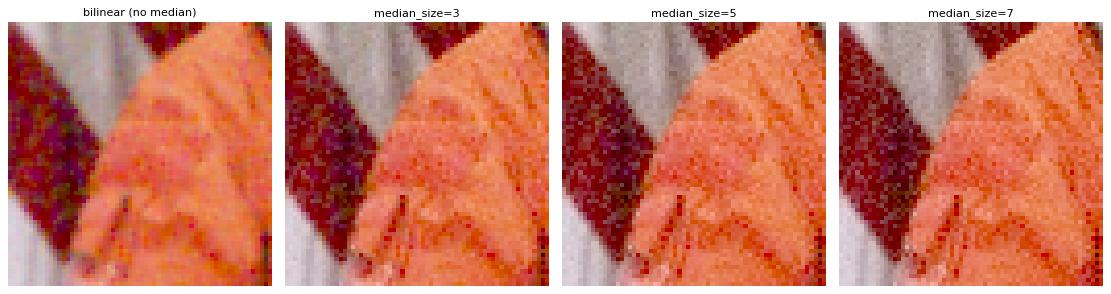

median_size 1: PSNR 27.41 dB, false colour 0.0333
median_size 3: PSNR 29.05 dB, false colour 0.0217
median_size 5: PSNR 28.70 dB, false colour 0.0192
median_size 7: PSNR 28.18 dB, false colour 0.0204


In [5]:
def median_sweep(img, sizes=(1, 3, 5, 7), noise=0.0, plot=True):
    m = cfa.mosaic(img)
    if noise:
        m = (m + utils.rng(0).normal(0, noise, m.shape)).astype(np.float32)
    outs, rows = {}, []
    for k in sizes:
        o = demosaic.demosaic(m, 'RGGB', 'bilinear') if k == 1 else demosaic.demosaic(m, 'RGGB', 'median', median_size=k)
        outs[k] = o
        rows.append((k, utils.psnr(img, o), demosaic.false_color(o, img)))
    if plot:
        show_row([srgb(np.clip(outs[k], 0, 1))[110:174, 0:64] for k in sizes],
                 [f'median_size={k}' if k > 1 else 'bilinear (no median)' for k in sizes], figsize=(14, 3.6))
    return rows

for noise in (0.0, 0.03):
    print(f'--- mosaic noise std {noise}')
    for k, p, f in median_sweep(scene, noise=noise, plot=(noise > 0)):
        print(f'median_size {k}: PSNR {p:5.2f} dB, false colour {f:.4f}')

Any median beats plain bilinear, and a small window is the sweet spot: a very large one starts to wipe out real colour edges. With noise the median also acts as a colour-noise filter, which is why the default camera in notebook 04 uses it.

## Two thirds of your data is made up

Only one of three channel values at each pixel was measured. The maps below show where the bilinear reconstruction differs from the truth, per channel: black where the sensor measured the value, brighter where it was interpolated.

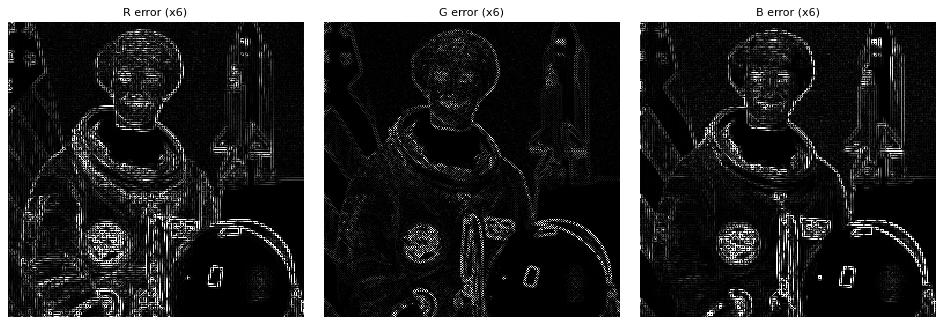

fraction of pixels where each channel was measured (R, G, B): [0.25 0.5  0.25]
share of the absolute error that sits on interpolated pixels: [1. 1. 1.]


In [6]:
def error_maps(img, method='bilinear', gain=6.0, plot=True):
    m = cfa.mosaic(img)
    out = demosaic.demosaic(m, 'RGGB', method)
    mk = cfa.masks(m.shape, 'RGGB')
    err = np.abs(out - img)
    share = [float(err[..., c][~mk[..., c]].sum() / err[..., c].sum()) for c in range(3)]
    if plot:
        show_row([np.clip(err[..., c] * gain, 0, 1) for c in range(3)],
                 [f'{n} error (x{gain:g})' for n in 'RGB'], cmap='gray', figsize=(12, 4), vmin=0, vmax=1)
    return dict(measured_fraction=[float(mk[..., c].mean()) for c in range(3)], error_share_at_interpolated=share)

r = error_maps(scene)
print('fraction of pixels where each channel was measured (R, G, B):', np.round(r['measured_fraction'], 2))
print('share of the absolute error that sits on interpolated pixels:', np.round(r['error_share_at_interpolated'], 3))

The measured pixels are exact and every bit of error sits on invented values: red and blue are measured on one pixel in four, green on one in two. Fine detail in the red and blue planes is therefore the hardest to recover, and the grid structure of the maps is the Bayer pattern itself.

## Luminance against chrominance (L3 s18-25)

Why is it acceptable to under-sample colour? Blur only the luma channel of a picture and you destroy it; blur only the chroma channels and it still looks sharp. JPEG (notebook 04) and luma/chroma denoising (notebook 03) rely on exactly this.

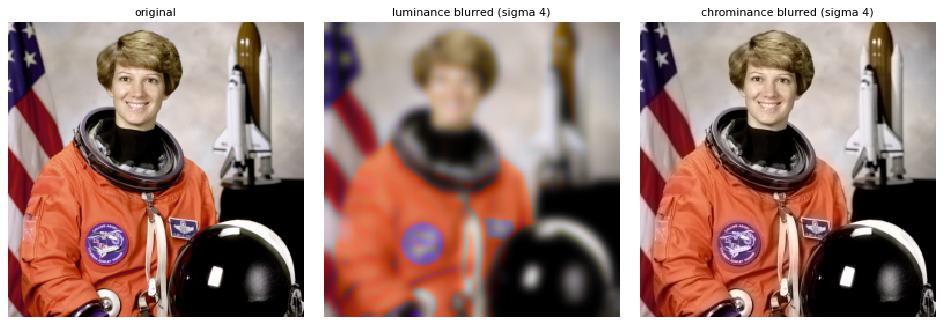

{'blur Y': 19.1, 'blur CbCr': 31.1} (PSNR dB vs original)


In [7]:
def luma_chroma_blur(img_display, sigma=4.0, plot=True):
    y = demosaic.blur_channel(img_display, 'Y', sigma)
    c = demosaic.blur_channel(img_display, 'CbCr', sigma)
    m = {'blur Y': utils.psnr(img_display, y), 'blur CbCr': utils.psnr(img_display, c)}
    if plot:
        show_row([img_display, y, c], ['original', f'luminance blurred (sigma {sigma:g})', f'chrominance blurred (sigma {sigma:g})'])
    return m

disp = srgb(scene)
print({k: round(v, 1) for k, v in luma_chroma_blur(disp).items()}, '(PSNR dB vs original)')

The chroma-blurred picture is hard to tell from the original while the luma-blurred one has lost its detail, although both used the same blur. The PSNR numbers agree with what you see.

## Colour temperature and the xy diagram (L4 s5-8)

Light sources are described by the temperature of a black body with the same colour: low temperatures are orange, high ones blue. On the CIE xy diagram the black-body colours form the Planckian locus; white balance has to undo where along that curve the light sits.

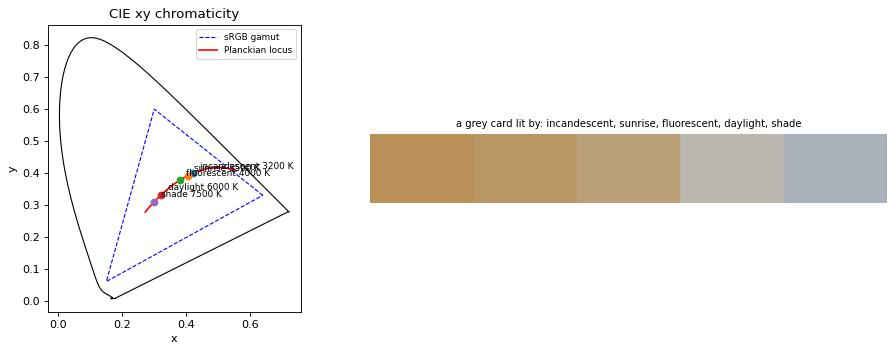

illuminant colours, G = 1 (R, G, B):
  incandescent  3200 K -> [1.91 1.   0.37]
  daylight      6000 K -> [1.11 1.   0.97]
  shade         7500 K -> [0.98 1.   1.19]


In [8]:
def xy_diagram(presets=('incandescent', 'sunrise', 'fluorescent', 'daylight', 'shade'), plot=True):
    locus = wb.spectral_locus_xy()
    T = np.linspace(1700, 12000, 120)
    pl = wb.planckian_locus_xy(T)
    gamut = wb.srgb_gamut_xy()
    pts = {k: wb.cct_to_xy(wb.PRESETS[k]) for k in presets}
    if plot:
        fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw=dict(width_ratios=[1, 1.2]))
        ax = axs[0]
        ax.plot(*np.vstack([locus, locus[:1]]).T, 'k-', lw=1)
        ax.plot(*np.vstack([gamut, gamut[:1]]).T, 'b--', lw=1, label='sRGB gamut')
        ax.plot(*pl.T, 'r-', label='Planckian locus')
        for k, (x, y) in pts.items():
            ax.plot(x, y, 'o'); ax.annotate(f'{k} {wb.PRESETS[k]} K', (x, y), textcoords='offset points', xytext=(6, 4), fontsize=8)
        ax.set_xlabel('x'); ax.set_ylabel('y'); ax.legend(fontsize=8); ax.set_aspect('equal'); ax.set_title('CIE xy chromaticity')
        sw = [srgb(np.clip(wb.apply_illuminant(np.full((40, 60, 3), 0.5, np.float32), wb.PRESETS[k]), 0, 1)) for k in presets]
        axs[1].imshow(np.concatenate(sw, axis=1)); axs[1].axis('off')
        axs[1].set_title('a grey card lit by: ' + ', '.join(presets), fontsize=9)
        plt.tight_layout(); plt.show()
    return pts

_ = xy_diagram()
print('illuminant colours, G = 1 (R, G, B):')
for k in ('incandescent', 'daylight', 'shade'):
    print(f'  {k:13s} {wb.PRESETS[k]} K ->', np.round(wb.illuminant_rgb(wb.PRESETS[k]), 2))

Tungsten sits at the orange end, shade at the blue end, and daylight lands near the neutral point (D65 is the white of sRGB). A grey card keeps its reflectance and takes on the colour of the light, which is why the sensor sees a cast instead of grey.

## Estimating the light: patch, gray world, white patch (L4 s9-11)

All three methods find gains $S_R, S_G, S_B$ and multiply the linear channels. They differ in how they guess the light: from a patch you say is neutral (`S_R = (R+G+B)/(3R)` on the slide), from the assumption that the scene averages to grey, or from the assumption that the brightest pixels are white. The error is the angle between the estimated and the true illuminant colour, which ignores brightness.

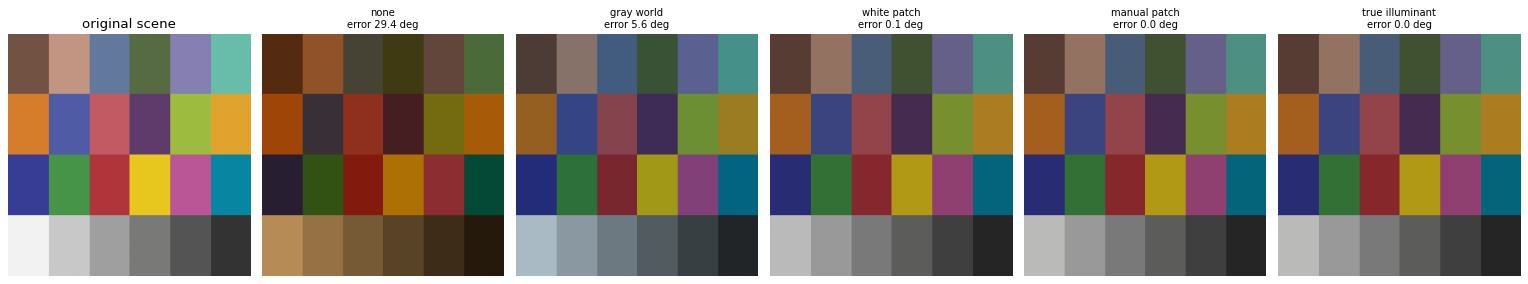

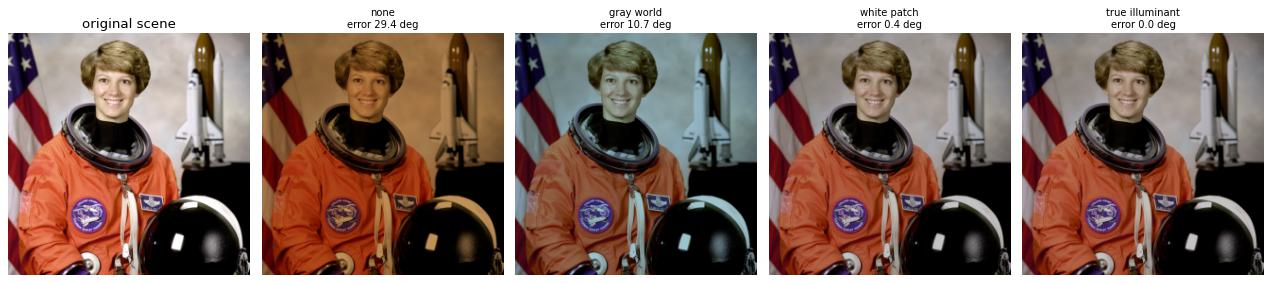

chart : {'none': 29.4, 'gray world': 5.6, 'white patch': 0.1, 'manual patch': 0.0, 'true illuminant': 0.0}
astro : {'none': 29.4, 'gray world': 10.7, 'white patch': 0.4, 'true illuminant': 0.0}


In [9]:
def compare_wb(img, T=3200, patch_box=None, plot=True):
    lit = wb.apply_illuminant(img, T)
    true_light = wb.gains_to_illuminant(wb.gains_for_illuminant(T))
    gains = {'none': np.ones(3, np.float32), 'gray world': wb.gray_world(lit), 'white patch': wb.white_patch(lit)}
    if patch_box is not None:
        gains['manual patch'] = wb.from_patch(lit, patch_box)
    gains['true illuminant'] = wb.gains_for_illuminant(T)
    errs = {k: wb.angular_error(wb.gains_to_illuminant(g), true_light) for k, g in gains.items()}
    if plot:
        n = len(gains)
        fig, axs = plt.subplots(1, n + 1, figsize=(3.2 * (n + 1), 3.6))
        axs[0].imshow(srgb(img)); axs[0].set_title('original scene'); axs[0].axis('off')
        for ax, (k, g) in zip(axs[1:], gains.items()):
            ax.imshow(srgb(np.clip(wb.apply_gains(lit, g) / (1.0 if k != 'none' else wb.illuminant_rgb(T).max()), 0, 1)))
            ax.set_title(f'{k}\nerror {errs[k]:.1f} deg', fontsize=9); ax.axis('off')
        plt.tight_layout(); plt.show()
    return errs

chart = scenes.patches(256)
boxes = scenes.patch_boxes(256)
errs_chart = compare_wb(chart, T=3200, patch_box=boxes[20])          # patch 20 is a neutral grey
errs_astro = compare_wb(scene, T=3200)
print('chart :', {k: round(v, 1) for k, v in errs_chart.items()})
print('astro :', {k: round(v, 1) for k, v in errs_astro.items()})

A neutral patch you point at (and the white patch, when the scene really contains white) gets the light almost exactly. Gray world is off because neither scene averages to grey; the astronaut has a lot of orange suit. Which automatic method is better depends on the scene; neither is right in general.

## When the assumptions fail: the sunset (L4 s10)

The sunset scene is orange on purpose. Its light is neutral (nothing to correct), but gray world sees a very orange average and tries to cancel it.

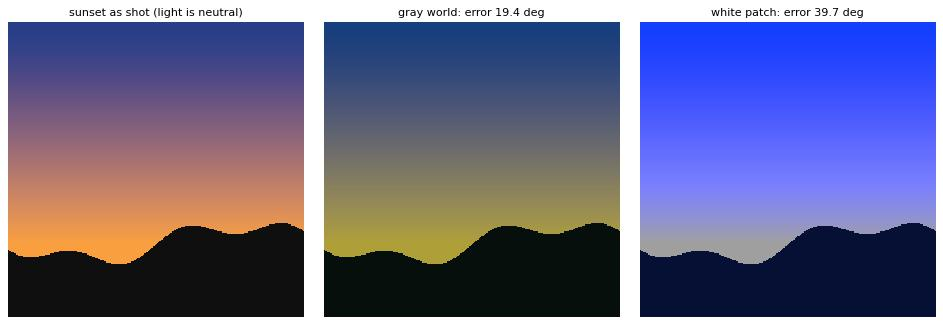

{'gray world': 19.4, 'white patch': 39.7}


In [10]:
def sunset_failure(plot=True):
    sun = scenes.sunset(256)
    truth = np.ones(3, np.float32)                       # neutral light: the right gains are all 1
    out = {}
    for name, g in (('gray world', wb.gray_world(sun)), ('white patch', wb.white_patch(sun))):
        out[name] = (wb.angular_error(wb.gains_to_illuminant(g), truth), wb.apply_gains(sun, g))
    if plot:
        show_row([srgb(sun)] + [srgb(np.clip(v[1], 0, 1)) for v in out.values()],
                 ['sunset as shot (light is neutral)'] + [f'{k}: error {v[0]:.1f} deg' for k, v in out.items()])
    return {k: v[0] for k, v in out.items()}

errs_sun = sunset_failure()
print({k: round(v, 1) for k, v in errs_sun.items()})

Both automatic methods are fooled. Gray world reads the orange as a cast and drags the horizon towards olive and the sky towards teal; white patch takes the brightest pixels (the orange horizon) as white and turns the sky a strong blue, which is even further off. Real cameras combine several estimators with priors on plausible illuminants.

## Interactive: illuminant and method

Pick a scene, the light and the estimator. The right panel is the corrected linear image shown through the sRGB curve.

In [11]:
_scenes_i = {n: scenes.load(n, 160) for n in ('astronaut', 'coffee', 'chelsea', 'sunset', 'patches')}

def wb_view(scene_name='astronaut', cct=3200, method='gray world'):
    img = _scenes_i[scene_name]
    lit = wb.apply_illuminant(img, cct)
    g = {'none': np.ones(3), 'gray world': wb.gray_world(lit), 'white patch': wb.white_patch(lit), 'true': wb.gains_for_illuminant(cct)}[method]
    err = wb.angular_error(wb.gains_to_illuminant(g), wb.gains_to_illuminant(wb.gains_for_illuminant(cct)))
    show_row([srgb(np.clip(lit, 0, 1)), srgb(np.clip(wb.apply_gains(lit, g), 0, 1))],
             [f'lit by {cct} K', f'{method}: gains {np.round(g, 2)}, error {err:.1f} deg'], figsize=(9, 4.2))

W.interact(wb_view, scene_name=list(_scenes_i), cct=W.IntSlider(min=2000, max=10000, step=250, value=3200),
           method=['none', 'gray world', 'white patch', 'true']);

interactive(children=(Dropdown(description='scene_name', options=('astronaut', 'coffee', 'chelsea', 'sunset', …

## Try it

1. In `compare_demosaic`, run the `coffee` and `chelsea` scenes and see whether the ranking of the five methods changes. Fur is a good stress test.
2. Add noise to the mosaic (as in `median_sweep`) and ask which method degrades most.
3. Run `compare_wb` for 6500 K and 9500 K. Why is the error of the true-illuminant row always about zero, and what does the error of `none` tell you about the strength of the cast?

In [12]:
# Exercises 1 and 3: edit the scene name / temperature and re-run
coffee = scenes.load('coffee', 256)
print({k: tuple(round(x, 3) for x in v) for k, v in compare_demosaic(coffee, plot=False).items()})
print({k: round(v, 1) for k, v in compare_wb(scene, T=9500, plot=False).items()})

{'nearest': (25.186, 0.042), 'bilinear': (30.274, 0.024), 'bicubic': (30.511, 0.024), 'median': (33.414, 0.017), 'malvar': (33.172, 0.018)}
{'none': 10.8, 'gray world': 14.4, 'white patch': 0.5, 'true illuminant': 0.0}
